# Forecasting Czech day-ahead electricity prices

**Task.** Every day before the day-ahead auction closes at **12:00 Prague time on day D**,
forecast the hourly price of the CZ bidding zone for every hour of **D+1**.

This notebook reports how well that works on more than two years of real data. It contains
no modelling logic of its own: features come from the dbt model `ml.ml_features_hourly`,
models and the backtest from `energy_pipeline.forecast`, and every table and chart from
`energy_pipeline.forecast.report`. Reproduce it from the repository root with

```bash
uv run forecast report            # uses the backtest outputs in data/forecast/
uv run forecast report --refresh  # re-runs validation, backtest and importance (~25 min)
```

In [1]:
import os

import altair as alt
import pandas as pd
from IPython.display import Markdown, display

from energy_pipeline.forecast import features, report

alt.renderers.enable("svg")  # static vector images: GitHub shows them, no JS needed
pd.set_option("display.precision", 2)

results = report.results(refresh=os.environ.get("FORECAST_REFRESH") == "1")
test = results.test

## 1. Known at the cutoff

A forecast is only honest if it uses what existed when it was made. Every input is known at
12:00 on D:

- the **calendar** of D+1;
- **prices of delivery days up to D**, published on D-1 around 13:00 (D+1 prices appear
  around 13:00 on D, after the cutoff);
- **weather forecasts published before the cutoff**: DWD ICON-EU runs initialised no later
  than 00Z on D, from Open-Meteo's archive of forecasts as they were issued.

The observed weather of D+1 is not known at the cutoff. It is used once below, as the upper
bound of what a perfect weather forecast could add, and never otherwise.

The rule is enforced in two places: dbt tests check, for every row, which price days and
which weather runs it used, and `tests/test_ml_features_leakage.py` builds the features of a
delivery day from warehouses with data after the cutoff absent, present, and altered, and
requires identical features.

In [2]:
groups = {
    "Calendar of D+1": features.CALENDAR,
    "Prices known on D": features.PRICES,
    "Weather forecast": features.WEATHER,
}
pd.DataFrame(
    [(group, len(columns), ", ".join(columns)) for group, columns in groups.items()],
    columns=["Group", "Features", "Columns"],
).style.hide(axis="index")

Group,Features,Columns
Calendar of D+1,12,"local_hour, hour_index, hours_in_day, is_peak, day_of_week, is_weekend, is_holiday, is_business_day, is_next_day_business_day, is_previous_day_business_day, month, day_of_year"
Prices known on D,14,"price_same_hour_d, price_same_hour_week_ago, price_same_hour_mean_7d, price_same_hour_min_7d, price_same_hour_max_7d, base_d, peak_d, offpeak_d, min_price_d, max_price_d, std_price_d, negative_hours_d, base_d_minus_1, base_mean_7d"
Weather forecast,11,"cz_temperature_c, cz_radiation_wm2, cz_wind_10m_ms, cz_wind_100m_ms, cz_cloud_cover_pct, de_solar_radiation_wm2, de_wind_100m_ms, cz_temperature_day_mean_c, cz_radiation_day_mean_wm2, de_solar_radiation_day_mean_wm2, de_wind_100m_day_mean_ms"


Czech weather is the mean of 8 points at the ČHMÚ stations; German solar comes from
three southern points (München, Nürnberg, Stuttgart) and German wind from three northern
ones (Husum, Emden, Magdeburg), since the CZ price is coupled with Germany's through SDAC.

## 2. Evaluation design

- **Walk-forward by day.** For each delivery day the model is trained on every delivery day
  up to D and predicts D+1, then the window moves one day. In the test it is refitted every
  day, as it would be in production.
- **Validation period** (2025-09-01 to 2026-02-28) to choose settings, **test period** (from
  2026-03-01) scored with the chosen settings only.
- **Benchmarks** to beat: the price at the same hour on D ("yesterday") and a week before D+1.
- **Metrics:** MAE and RMSE in EUR/MWh. No MAPE: prices are often zero or negative.
- **Models:** Ridge (linear, the hour, weekday and month one-hot) and LightGBM (gradient
  boosted trees), each with no weather, the weather forecast, or observed weather.

## 3. Choices made on the validation period

In [3]:
results.validation[["variant", "mae", "rmse", "mae_peak", "mae_offpeak"]].rename(
    columns={"variant": "Candidate (weather forecast)"}
).style.hide(axis="index").format(precision=2)

Candidate (weather forecast),mae,rmse,mae_peak,mae_offpeak
benchmark,22.75,35.61,29.62,15.89
benchmark,25.54,39.95,32.15,18.93
ridge alpha=1 relative=True,17.11,25.57,20.32,13.91
ridge alpha=10 relative=True,17.04,25.50,20.25,13.83
ridge alpha=100 relative=True,16.76,25.25,20.03,13.49
ridge alpha=1000 relative=True,16.62,25.25,19.92,13.33
ridge alpha=10000 relative=True,17.31,26.63,21.31,13.31
ridge alpha=1 relative=False,17.11,25.56,20.32,13.91
ridge alpha=10 relative=False,17.04,25.50,20.24,13.83
ridge alpha=100 relative=False,16.70,25.22,19.92,13.48


- **Target: the price itself.** Predicting the deviation from the last week's mean price
  at the same hour was the starting hypothesis (trees cannot extrapolate to price levels they
  have not seen). It was worse for both models and was dropped.
- **LightGBM** with the L1 loss (the metric is MAE) and 500 trees; 1000 trees were no
  better. **Ridge** with alpha = 1000, the optimum inside the grid.
- **Intervals.** Quantile models (p10, p50, p90) were overconfident; conformalizing them
  on the last 28 training days brought the validation coverage to the nominal 80 %:

In [4]:
results.validation_intervals.rename(columns={"variant": "Candidate"}).drop(
    columns="model"
).style.hide(axis="index").format(precision=3)

Candidate,coverage_p10_p90,mean_width,pinball_p10,pinball_p50,pinball_p90
lightgbm quantiles calibration_days=0,0.699,36.263,3.084,6.988,4.073
lightgbm quantiles calibration_days=28,0.798,45.027,3.174,7.127,4.048


## 4. Results on the test period

In [5]:
facts = report.period_facts(test)
summary = report.test_summary(test)
by_model = summary.set_index("Model")
main = by_model.loc["LightGBM, weather forecast"]
yesterday = by_model.loc["Benchmark: same hour yesterday"]
week_ago = by_model.loc["Benchmark: same hour a week ago"]
daily = report.daily_mae(test)
display(
    Markdown(
        f"Test period: **{facts['first_day']} to {facts['last_day']}**, "
        f"{facts['days']} delivery days, {facts['hours']:,} hours.\n\n"
        f"LightGBM with the weather forecast: **MAE {main['MAE']:.2f} EUR/MWh**, against "
        f"{yesterday['MAE']:.2f} for the same hour yesterday ({main['MAE vs yesterday']:+.0%}) "
        f"and {week_ago['MAE']:.2f} for a week ago. It has the lower daily MAE on "
        f"{(daily['LightGBM'] < daily['Same hour yesterday']).sum()} of {len(daily)} days."
    )
)
summary.style.hide(axis="index").format(
    {
        "MAE vs yesterday": "{:+.0%}",
        "MAE": "{:.2f}",
        "RMSE": "{:.2f}",
        "MAE peak": "{:.2f}",
        "MAE off-peak": "{:.2f}",
    }
)

Test period: **2026-03-01 to 2026-10-29**, 243 delivery days, 5,832 hours.

LightGBM with the weather forecast: **MAE 21.29 EUR/MWh**, against 32.45 for the same hour yesterday (-34%) and 38.76 for a week ago. It has the lower daily MAE on 193 of 243 days.

Model,MAE,RMSE,MAE peak,MAE off-peak,MAE vs yesterday
Benchmark: same hour yesterday,32.45,49.41,38.41,26.48,+0%
Benchmark: same hour a week ago,38.76,57.89,44.94,32.59,+19%
"Ridge, no weather",27.63,40.04,31.56,23.70,-15%
"LightGBM, no weather",25.85,39.96,30.13,21.57,-20%
"Ridge, weather forecast",24.10,36.20,27.24,20.97,-26%
"LightGBM, weather forecast",21.29,34.00,24.60,17.97,-34%
"Ridge, observed weather (upper bound)",23.70,35.55,26.63,20.76,-27%
"LightGBM, observed weather (upper bound)",21.09,33.61,24.26,17.93,-35%


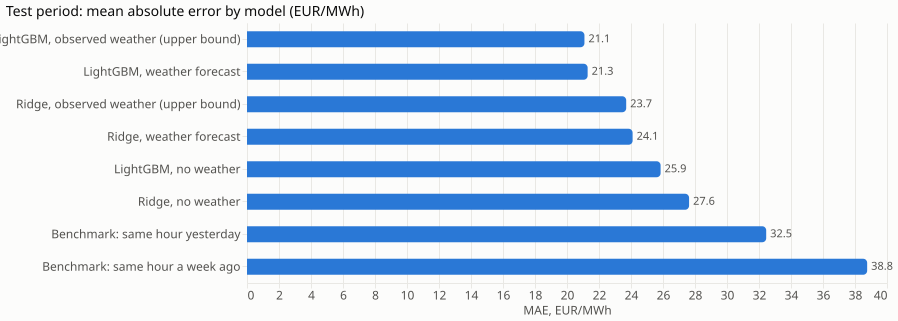

In [6]:
report.mae_by_model_chart(test)

### What the weather is worth

The same models without weather, with the forecast, and with the weather that actually
happened in Czechia (German inputs stay forecasts there: no German observations are in the
warehouse):

In [7]:
value = report.weather_value(test)
lgb = value.loc["lightgbm"]
display(
    Markdown(
        f"For LightGBM the weather forecast cuts the MAE by "
        f"**{lgb['no_weather'] - lgb['weather_forecast']:.1f} EUR/MWh**; perfect Czech weather "
        f"would cut it by only {lgb['weather_forecast'] - lgb['weather_observed']:.1f} more. "
        "Better Czech weather data is not where the remaining error is."
    )
)
value

For LightGBM the weather forecast cuts the MAE by **4.6 EUR/MWh**; perfect Czech weather would cut it by only 0.2 more. Better Czech weather data is not where the remaining error is.

variant,no_weather,weather_forecast,weather_observed
model,,,
ridge,27.63,24.10,23.70
lightgbm,25.85,21.29,21.09


### Over time

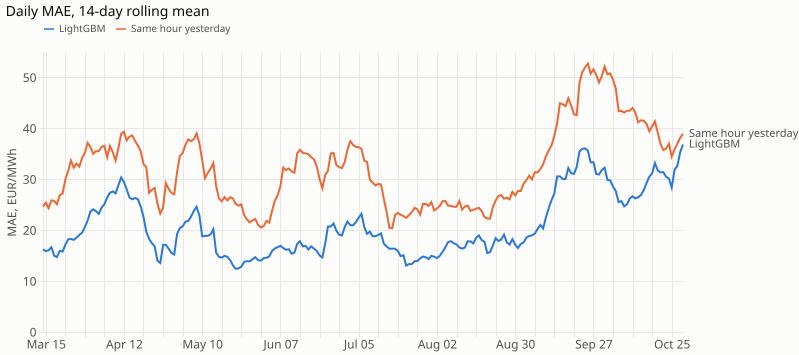

In [8]:
report.rolling_mae_chart(test)

In [9]:
report.by_group(test, "season").round(2)

series,LightGBM,Same hour yesterday
season,,
spring,18.78,29.37
summer,17.41,28.75
autumn,31.24,42.99


The model beats the benchmark throughout. Both errors rise in autumn 2026, when prices
were higher and swung more than anything in the training history.

### By hour of the day

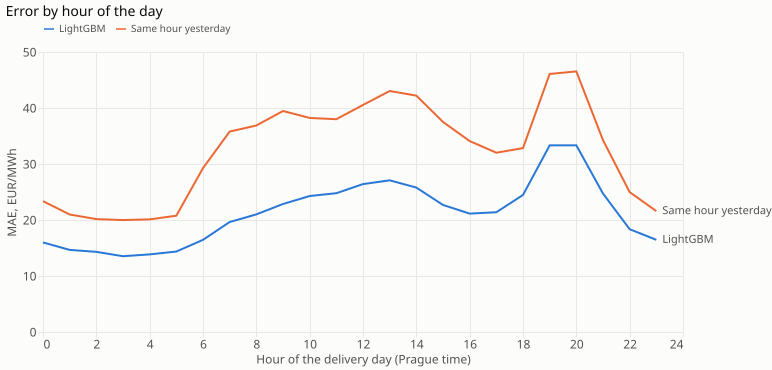

In [10]:
report.mae_by_hour_chart(test)

Nights are easiest. Midday carries the solar uncertainty, and the evening ramp at
19:00-20:00, when solar output disappears and demand peaks, is the hardest hour for both.

### Forecasts against actual prices

The last week of the test, with the autumn DST day (25 hours) on Sunday 25 October:

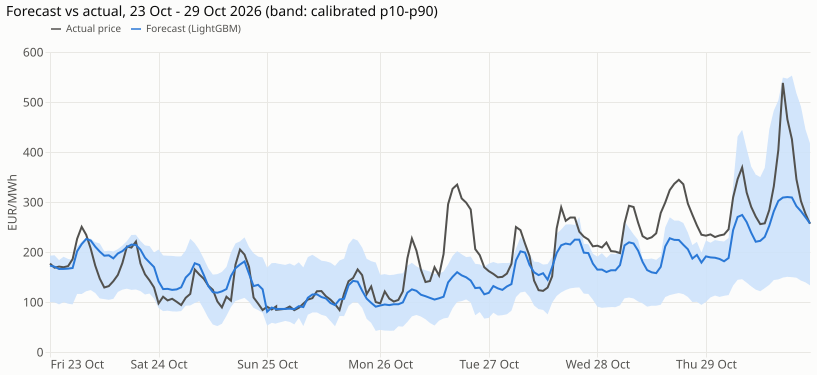

In [11]:
report.forecast_vs_actual_chart(test, test["delivery_date"].max() - pd.Timedelta(days=6))

And the week of 1 May 2026, when the price hit the harmonised floor of -500 EUR/MWh at
midday. The model expects a negative price but has never seen anything like the floor:

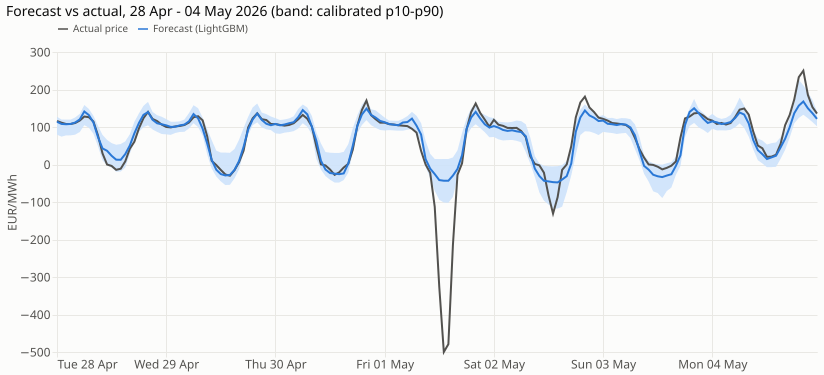

In [12]:
report.forecast_vs_actual_chart(test, pd.Timestamp("2026-04-28").date())

### Prediction intervals

In [13]:
intervals = report.interval_summary(test)
row = intervals.iloc[0]
display(
    Markdown(
        f"The calibrated p10-p90 interval contains **{row['coverage_p10_p90']:.1%}** of the "
        f"test hours (80 % nominal), with a mean width of {row['mean_width']:.0f} EUR/MWh."
    )
)
intervals.drop(columns=["model", "variant"]).style.hide(axis="index").format(precision=3)

The calibrated p10-p90 interval contains **75.6%** of the test hours (80 % nominal), with a mean width of 69 EUR/MWh.

coverage_p10_p90,mean_width,pinball_p10,pinball_p50,pinball_p90
0.756,69.449,5.598,11.726,5.734


Without the calibration the quantile models covered about 63 % of the test hours. The
calibrated interval is still somewhat narrow, because prices in autumn 2026 varied more than
in the four weeks the margin is taken from.

## 5. What drives the forecast

Mean absolute SHAP value per feature on the test hours, in EUR/MWh: how far, on average,
each feature moves a forecast (LightGBM with the weather forecast, trained on everything
before the test period).

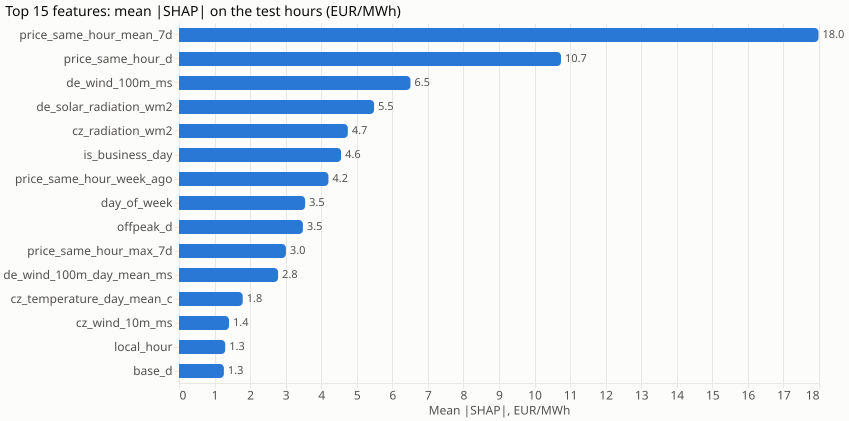

In [14]:
report.importance_chart(results.importance)

Recent prices set the level. Weather then moves it hour by hour, and **German wind and
solar matter more than Czech weather**, which fits a price set in a coupled market dominated
by German renewables.

## 6. What worked, what did not, limitations

**Worked**

- Strict "known at the cutoff" features, enforced by tests rather than by care.
- Archived weather forecasts as they were issued: the forecast captures almost all of the
  value observed weather would have.
- German wind and solar forecasts as features.
- LightGBM with an L1 loss; conformal calibration of the intervals.

**Did not work**

- Predicting the deviation from the recent price level instead of the price.
- Uncalibrated quantile regression: far too confident.

**Limitations**

- The test period was scored twice: once with raw quantile intervals, once after adding the
  calibration (chosen on the validation period). Point forecasts did not change.
- That Open-Meteo's archived values come from the run N days earlier was verified only from
  2026-04-02, when its single-run archive starts.
- No fuel or CO2 prices, cross-border flows, outages or load forecasts: much of the autumn
  error and the extreme hours (the -500 floor) are out of reach of these features.
- One hole in the forecast archive (2026-04-07 to 11) is left as missing values.

Method details: [docs/forecasting.md](../docs/forecasting.md); weather data:
[docs/sources.md](../docs/sources.md), section 5. Weather data by
[Open-Meteo.com](https://open-meteo.com/) (CC BY 4.0).